# 教程 01 — 零数据下载：3 分钟玩转 8 篇脑机接口顶刊解码流水线
**Zero-Download Playground: Exploring 8 Intracortical Communication BCI Reproductions**
*Language: [English Version](../01_zero_download_results_playground.ipynb) | **中文版***

欢迎来到 `communication-neuroprostheses-reproduction`！
对于刚 clone 仓库的同学来说，从 Dryad 下载上百 GB 的原始神经电生理数据（`.mat` / `.hdf5`）往往需要几个小时。为了让你可以**在 3 分钟内零下载直接上手**，我们在每个研究子目录的 `results/` 下完整归档了单卡复现跑出的**逐句（per-trial）解码输出、音素错误率（PER）与词错误率（WER）记录**。

在本 Notebook 中，你将亲手跑通以下 4 个核心实验：
1. **全景扫描**：一键读取 `reproduction_benchmark.yaml`，对比 8 篇 *Nature* / *NEJM* / *Cell* / *NeurIPS* 论文的模态、词表规模、家用电脑内存/显存峰值与复现精度。
2. **解码流水线逐级解剖（Willett 2023 & Card 2024）**：对比同一句话在 **Greedy 音素解码 → 3-gram KenLM → 125k 5-gram WFST → OPT-6.7B / Qwen3-8B** 各阶段是如何一步步把同音错词纠正回来的。
3. **语言模型“相变边界”（PER vs. WER Phase Diagram）**：重绘主图 Panel (i)，直观理解为什么当声学/音素错误率 $\text{PER} < 25\%$ 时大语言模型能大幅降错，而当 $\text{PER} > 30\%$ 时反而会引发幻觉雪崩。
4. **403 天跨日神经漂移与 CORP 无监督自校准（Fan 2023）**：可视化植入电极在一年多时间里的信号漂移，以及在线伪标签微调如何将字符错误率（CER）压回 $6.20\%$。

In [1]:
from pathlib import Path
import csv
import json
import re
import yaml
import editdistance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 定位仓库根目录（无论从根目录还是 tutorials/ 启动均可正常工作）
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reproduction_benchmark.yaml").exists())
print(f"Repository root: {REPO_ROOT}")

with open(REPO_ROOT / "reproduction_benchmark.yaml", encoding="utf-8") as f:
    bench = yaml.safe_load(f)

print("Hardware baseline:", bench["hardware_spec"])

Repository root: D:\repositories\20261106_communication_neuroprostheses_reproduction
Hardware baseline: {'gpu': '1x NVIDIA RTX 5060 Ti (16 GB VRAM)', 'host_ram_gb': 64.0, 'gpu_vram_gb': 16.0}


## 1. 全景对比：8 篇脑机接口论文的复现成绩单

我们先从 `reproduction_benchmark.yaml` 中提取声学/字符阶段指标（Panel e）、端到端词错误率 WER（Panel f）以及主机内存/显存峰值（Panels g–h），汇总成一张清晰的数据表。

In [2]:
summary_rows = []
for ac, wf in zip(bench["panel_e_repro_acoustic"], bench["panel_f_repro_full_wer"]):
    label_clean = ac["label"].replace("\n", " ")
    summary_rows.append({
        "Study & Participant": label_clean,
        "Acoustic (Ours %)": ac["ours"],
        "Acoustic (Paper %)": ac["paper"],
        "Full-Pipeline WER (Ours %)": wf["ours"],
        "Full-Pipeline WER (Paper %)": wf["paper"],
        "Note": wf["note"].replace("\n", " ") if wf["note"] else (ac["note"] or ""),
    })

summary_table = pd.DataFrame(summary_rows)
print(summary_table.to_string(index=False))

                    Study & Participant  Acoustic (Ours %)  Acoustic (Paper %)  Full-Pipeline WER (Ours %)  Full-Pipeline WER (Paper %)                   Note
     Willett et al., 2021 (T5, raw CER)               4.71                2.78                       10.00                         3.64     bigram 63-tr. pool
 Willett et al., 2023 (T12, greedy PER)              23.42               19.70                       23.58                        23.80        day med. 5-gram
     Fan et al., 2023 (T5, CORP v6 CER)               6.20                6.16                        4.10                         6.16    recal. arm 10 sess.
    Card et al., 2024 (T15, greedy PER)              10.19                9.54                        6.25                         6.70    41-s pool biGRU-48k
Wairagkar et al., 2025 (T15, 1−mel r %)              31.40               17.00                         NaN                          NaN WER n/r (voice; see e)
    Kunz et al., 2025 (T12, greedy PER)       

## 2. 语音脑机接口流水线逐级解剖：从音素序列到 LLM 重打分

在 **Willett et al. (*Nature* 2023, T12)** 和 **Card et al. (*NEJM* 2024, T15)** 中，神经解码器并不是直接输出英文单词，而是分成三步：
1. **声学阶段（5 层 GRU + CTC Loss）**：将每 20 ms 的神经脉冲特征映射为 40 个英语音素（ARPAbet）+ 词边界（SIL）+ CTC blank 的帧级后验概率。
2. **第一遍语言模型解码（WFST Beam Search）**：用发声词典（125,000 词）和 n-gram 语言模型把音素概率流搜索成候选词序列（N-best 词网格）。
3. **第二遍大语言模型重打分（OPT-6.7B / Qwen3-8B Rescoring）**：利用自回归因果大语言模型计算整句通顺度，按综合得分 $\text{score} = s_{\text{acoustic}} + \alpha \cdot \log P_{\text{LM}}(w) + \beta \cdot |w|$ 选出最优句子。

下面我们直接读取 `20230831_willett/results/decode_outputs/` 中归档的 4 个不同解码阶段文件，采用官方 `shared/tools/wer_from_tsv.py` 的分词口径实时重算全测试集 WER，并挑出几个经典试次看语言模型是如何“力挽狂澜”的！

In [3]:
import sys
sys.path.insert(0, str(REPO_ROOT))
from build_session_per_vs_wer import read_tsv

def norm_tokens(sent: str) -> list[str]:
    """Official sidecar tokenization (matches shared/tools/wer_from_tsv.py)."""
    return re.sub(r"[^A-Za-z'< ]", " ", sent).upper().split()

def compute_official_wer(pairs: list[tuple[str, str]]) -> float:
    tot_ed, tot_ref = 0, 0
    for ref, hyp in pairs:
        r_tok = norm_tokens(ref)
        h_tok = norm_tokens(hyp)
        tot_ed += editdistance.eval(r_tok, h_tok)
        tot_ref += len(r_tok)
    return 100.0 * tot_ed / max(1, tot_ref)

willett_dir = REPO_ROOT / "20230831_willett" / "results" / "decode_outputs"

with open(willett_dir / "word_decode_joint3gram.csv", encoding="utf-8") as f:
    rows_3g = [(r["sentence_label"], r["hyp_words"]) for r in csv.DictReader(f)]

rows_5g = read_tsv(willett_dir / "wl_final_full.tsv")
rows_opt = read_tsv(willett_dir / "wl_5g_opt_official.tsv")
rows_qwen = read_tsv(willett_dir / "wl_5g_opt_qwen3base_fx.tsv")

print("=== Willett et al. (Nature 2023, T12) 解码各阶段实测 Pooled WER ===")
for stage_name, pairs in [
    ("Stage 1a: 1.46 GB KenLM 3-gram Beam Search", rows_3g),
    ("Stage 1b: 19.6 GB Kaldi 125k 5-gram WFST (1-best)", rows_5g),
    ("Stage 2a: 5-gram N-best + OPT-6.7B Rescoring (FP16)", rows_opt),
    ("Stage 2b: 5-gram N-best + Qwen3-8B Rescoring (4-bit)", rows_qwen),
]:
    print(f"  {stage_name:<52s} -> WER = {compute_official_wer(pairs):.2f}%  ({len(pairs)} trials)")

print("\n=== 逐句对比：看 5-gram 与大语言模型如何纠正同音近音词 ===")
for idx in [3, 4, 8, 14]:
    ref = rows_5g[idx][0]
    print(f"\n[Trial #{idx:04d}]")
    print(f"  Ground Truth : {ref}")
    print(f"  3-gram KenLM : {rows_3g[idx][1]}")
    print(f"  5-gram WFST  : {rows_5g[idx][1]}")
    print(f"  + OPT-6.7B   : {rows_opt[idx][1]}")
    print(f"  + Qwen3-8B   : {rows_qwen[idx][1].upper()}")

=== Willett et al. (Nature 2023, T12) 解码各阶段实测 Pooled WER ===
  Stage 1a: 1.46 GB KenLM 3-gram Beam Search           -> WER = 31.76%  (880 trials)
  Stage 1b: 19.6 GB Kaldi 125k 5-gram WFST (1-best)    -> WER = 24.85%  (880 trials)
  Stage 2a: 5-gram N-best + OPT-6.7B Rescoring (FP16)  -> WER = 23.22%  (880 trials)
  Stage 2b: 5-gram N-best + Qwen3-8B Rescoring (4-bit) -> WER = 24.11%  (880 trials)

=== 逐句对比：看 5-gram 与大语言模型如何纠正同音近音词 ===

[Trial #0003]
  Ground Truth : Lori's costume needed black gloves to be completely elegant.
  3-gram KenLM : TO CUSTOM NEED BACK LOVE TO BE SOME EATER ELLEN
  5-gram WFST  : CUSTOM MADE BLACK LIVES TO BE COMPLETELY ALIEN
  + OPT-6.7B   : TWO CUSTOM MADE BLACK GLOVES TO BE COMPLETELY ALONE
  + Qwen3-8B   : CUSTOM NEED BACK LOVE TO BE COMPLETELY ALONE

[Trial #0004]
  Ground Truth : The tooth fairy forgot to come when Roger's tooth fell out.
  3-gram KenLM : THE TRUTH VERY FORGOT TO COME WHEN WESTERVELT OUT
  5-gram WFST  : THE TRUTH WE WANT TO COME WHEN 

## 3. 语言模型的“相变边界”：为什么音素错误率超过 25%–30% 时 WER 会雪崩？

很多初学者都会问：**“既然大语言模型这么强，如果前端神经解码器的音素错误率（PER）是 50%，能不能靠 GPT/Qwen 猜出正确句子？”**

答案是**不能，甚至会越改越错**。我们读取根目录下的 `session_per_vs_wer.json`（由 `build_session_per_vs_wer.py` 从所有归档试次精确聚合而成），把 4 篇语音论文、6 位受试者队列的每一个实验日（Session）画在 **(Greedy PER, Post-LM WER)** 平面上：

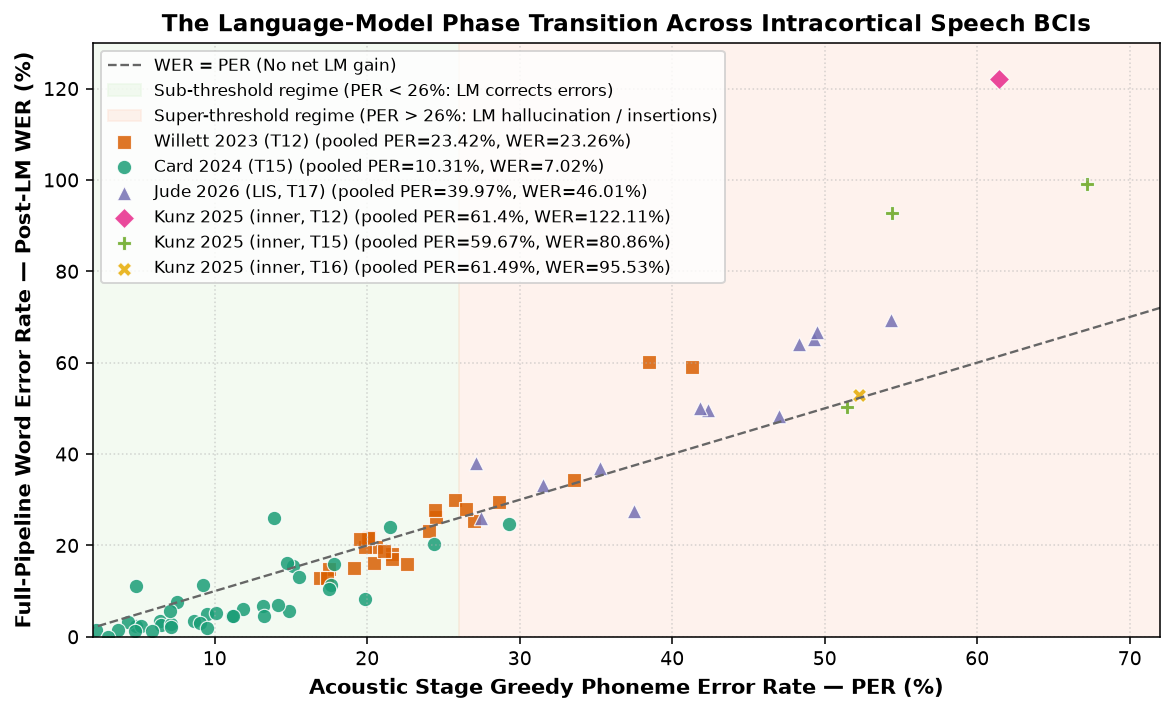

In [4]:
with open(REPO_ROOT / "session_per_vs_wer.json", encoding="utf-8") as f:
    phase_data = json.load(f)

fig, ax = plt.subplots(figsize=(8.5, 5.2))

palette = {
    "Card 2024 (T15)": ("#1b9e77", "o"),
    "Willett 2023 (T12)": ("#d95f02", "s"),
    "Jude 2026 (LIS, T17)": ("#7570b3", "^"),
    "Kunz 2025 (inner, T12)": ("#e7298a", "D"),
    "Kunz 2025 (inner, T15)": ("#66a61e", "P"),
    "Kunz 2025 (inner, T16)": ("#e6ab02", "X"),
}

x_grid = np.linspace(0, 80, 200)
ax.plot(x_grid, x_grid, ls="--", color="#666666", lw=1.2, label="WER = PER (No net LM gain)")
ax.axvspan(0, 26, color="#e5f5e0", alpha=0.45, label="Sub-threshold regime (PER < 26%: LM corrects errors)")
ax.axvspan(26, 75, color="#fee0d2", alpha=0.40, label="Super-threshold regime (PER > 26%: LM hallucination / insertions)")

for study_name, content in phase_data.items():
    color, marker = palette.get(study_name, ("#333333", "o"))
    pers = [s["per"] for s in content["sessions"]]
    wers = [s["wer"] for s in content["sessions"]]
    ax.scatter(
        pers, wers, c=color, marker=marker, s=55, alpha=0.85, edgecolors="white", linewidth=0.6,
        label=f"{study_name} (pooled PER={content['pooled']['per']}%, WER={content['pooled']['wer']}%)"
    )

ax.set_xlim(2, 72)
ax.set_ylim(0, 130)
ax.set_xlabel("Acoustic Stage Greedy Phoneme Error Rate — PER (%)", fontsize=11, fontweight="bold")
ax.set_ylabel("Full-Pipeline Word Error Rate — Post-LM WER (%)", fontsize=11, fontweight="bold")
ax.set_title("The Language-Model Phase Transition Across Intracortical Speech BCIs", fontsize=12, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(loc="upper left", fontsize=8.5, frameon=True)
plt.tight_layout()
plt.show()

从上图可以清晰看到两条物理规律：
* **绿区（$\text{PER} < 26\%$，如 Card 2024 T15 与 Willett 2023 T12）**：所有数据点都落在对角线下方（$\text{WER} < \text{PER}$）。在 T15 上，$10.19\%$ 的音素错误率经过 5-gram + OPT 重打分后，词错误率被压低到了 $7.02\%$（BiGRU 41-session 池化达 $6.25\%$）。
* **红区（$\text{PER} > 30\%$，如 Jude 2026b T17 闭锁综合征对话集与 Kunz 2025 内心言语小样本从头训练）**：当音素流太模糊时，WFST 束搜索为了凑出合法的英语单词，会把一个长词切碎成多个短词（引发大量插入错误 Insertions），导致 $\text{WER} > \text{PER}$ 甚至超过 $100\%$。

---

## 4. 跨越 403 天的神经信号漂移与 CORP 无监督自校准（Fan et al., *NeurIPS* 2023）

植入微电极阵列（Utah Array）面临的另一个核心挑战是**跨天信号漂移（Day-to-Day Neural Drift）**。如果把第 1 天训好的解码器冻结不动（Frozen Seed Model），几周后错误率就会飙升。
**Fan et al. (*NeurIPS* 2023)** 提出了 **CORP**（利用语言模型纠正后的伪标签，在用户打字过程中后台无监督微调解码器）。我们直接读取 `20231201_fan/results/` 下的两组实测 JSON，画出这 403 天里 10 个随访 Session 的对比曲线：

Day-0 Seed CER: 2.65% | Frozen Static 403-day CER: 50.85% | CORP v6 Adapted CER: 6.20%


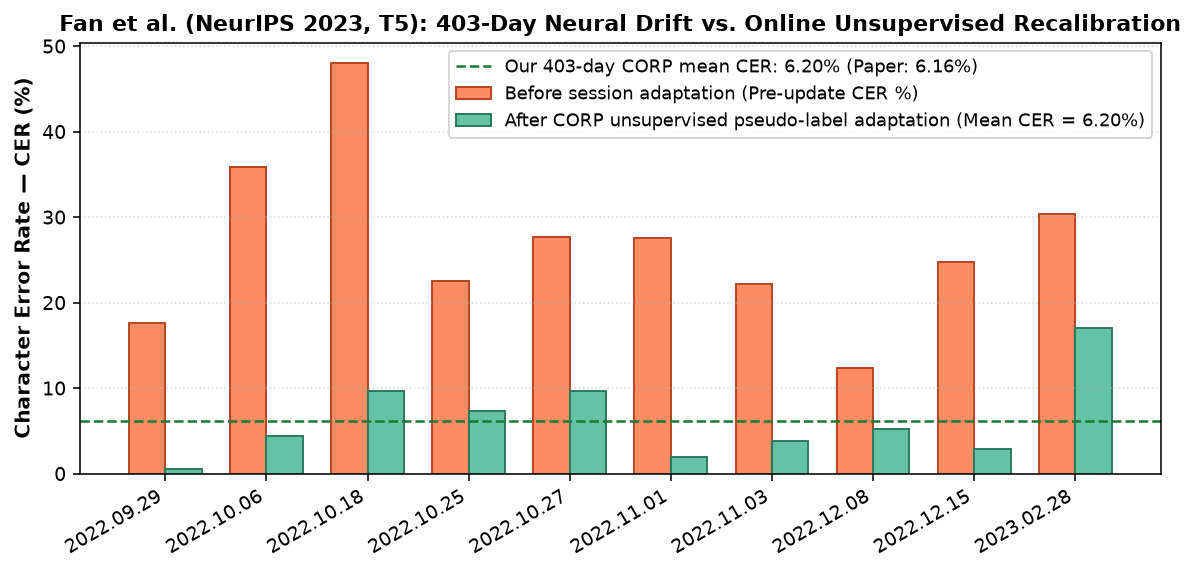

In [5]:
fan_dir = REPO_ROOT / "20231201_fan" / "results"
with open(fan_dir / "tier2_seed_model_inference.json", encoding="utf-8") as f:
    tier2_frozen = json.load(f)
with open(fan_dir / "tier3_corp_sim_v6.json", encoding="utf-8") as f:
    tier3_corp = json.load(f)

sessions = [s["session"] for s in tier3_corp["sessions"]]
pre_cer = [s["pre"] for s in tier3_corp["sessions"]]
corp_post_cer = [s["post"] for s in tier3_corp["sessions"]]

mean_post = tier3_corp["summary"]["mean_post"]
static_ref = tier3_corp["summary"]["static_ref"]
seed_cer = tier2_frozen["seed_selftest"]["pooled_cer_pct"]
print(f"Day-0 Seed CER: {seed_cer:.2f}% | Frozen Static 403-day CER: {static_ref:.2f}% | CORP v6 Adapted CER: {mean_post:.2f}%")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(sessions))
width = 0.36

ax.bar(x - width/2, pre_cer, width, color="#fc8d62", edgecolor="#b34820",
       label="Before session adaptation (Pre-update CER %)")
ax.bar(x + width/2, corp_post_cer, width, color="#66c2a5", edgecolor="#2b7a5f",
       label=f"After CORP unsupervised pseudo-label adaptation (Mean CER = {mean_post:.2f}%)")

ax.axhline(mean_post, color="#1b7837", ls="--", lw=1.3,
           label=f"Our 403-day CORP mean CER: {mean_post:.2f}% (Paper: 6.16%)")
ax.set_xticks(x)
ax.set_xticklabels([s.replace("t5.", "") for s in sessions], rotation=30, ha="right")
ax.set_ylabel("Character Error Rate — CER (%)", fontsize=10.5, fontweight="bold")
ax.set_title("Fan et al. (NeurIPS 2023, T5): 403-Day Neural Drift vs. Online Unsupervised Recalibration",
             fontsize=11.5, fontweight="bold")
ax.grid(axis="y", linestyle=":", alpha=0.5)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 动手练习（给学生与 AI Agent 的探索建议）
1. **换用不同大语言模型重打分**：在上面第 2 节中，把 `20230831_willett` 换成 `20260428_jude/results/decode_outputs/`，对比 `off_5g_opt_official.tsv`（OPT-6.7B）与 `off_5g_opt_qwen3base_fx.tsv`（Qwen3-8B）在闭锁综合征患者 T17 上的表现差异。
2. **接下来看什么？**
   - 打开 [`02_memory_wall_autopsy_16gb_gpu.ipynb`](02_memory_wall_autopsy_16gb_gpu_zh.ipynb)：亲手在你的显卡上测试为什么原版代码需要 300 GB 内存 + 80 GB A100，以及我们如何用 `mmap` + BF16 + cuDNN 单层栈把显存压进 16 GB。
   - 打开 [`03_single_session_end_to_end_demo.ipynb`](03_single_session_end_to_end_demo_zh.ipynb)：在几秒钟内从零训练一个 `InputNet + TypingGRU` 脑机接口解码器并完成 CTC + 词典语言模型解码。